# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 1. Vẽ chuỗi thời gian → nhận diện mùa vụ

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

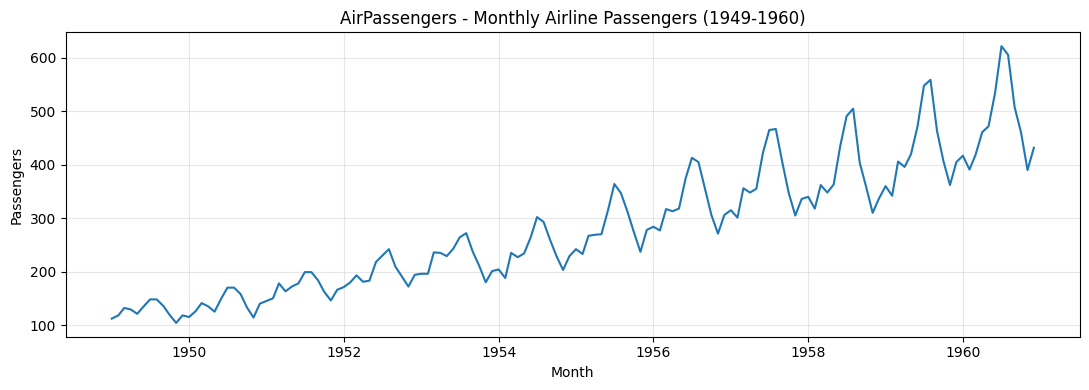

In [2]:
plt.figure(figsize=(11, 4))
plt.plot(y)
plt.title("AirPassengers - Monthly Airline Passengers (1949-1960)")
plt.xlabel("Month"); plt.ylabel("Passengers"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

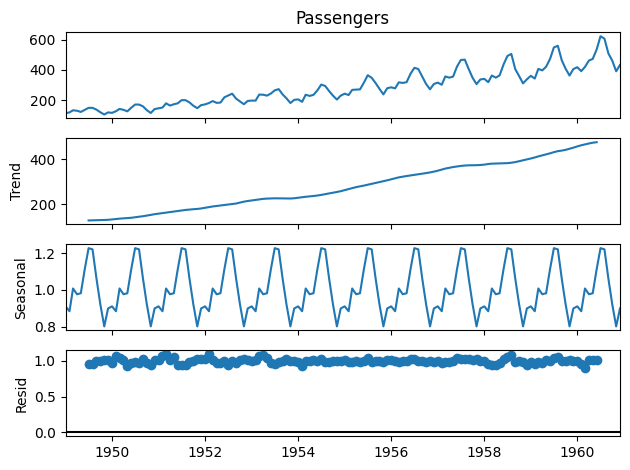

In [3]:
seasonal_decompose(y, model="multiplicative", period=S).plot()
plt.tight_layout(); plt.show()

**Nhận xét:** chuỗi có xu hướng tăng và mùa vụ lặp lại mỗi 12 tháng (s = 12). Biên độ mùa vụ tăng dần theo thời gian nên đây là mùa vụ nhân (multiplicative).